# Kernel SVM

A Kernel SVM measures how **similar** penguins are, so its boundary can curve instead of staying straight. The `rbf` kernel is the usual choice.

This notebook goes with the **Kernel SVM** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → scale → fit the model → check the result → draw the decision boundary.

## 1. Load the data

Each row is a penguin. We have two measurements (**bill length** and **body mass**) and the species. The goal: predict whether a penguin is an **Adelie** or a **Chinstrap** from those two numbers.

The data is the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) data set (CC0), reduced to two species and two columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/penguins.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,species,bill_length_mm,body_mass_g
0,Adelie,39.1,3750
1,Adelie,39.5,3800
2,Adelie,40.3,3250
3,Adelie,36.7,3450
4,Adelie,39.3,3650


In [2]:
X = dataset[['bill_length_mm', 'body_mass_g']].values
y = (dataset['species'] == 'Chinstrap').astype(int).values  # 0 = Adelie, 1 = Chinstrap

print(X.shape, 'penguins, class counts:', np.bincount(y))

(219, 2) penguins, class counts: [151  68]


## 2. Split into train and test

The model learns from the **training** penguins (75%). We keep the other 25% hidden and only use them at the end, so the test score shows how the model does on penguins it has never seen. Those are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

164 train, 55 test


## 3. Scale the features

The kernel uses distances, so scale the features first.

`StandardScaler` shifts each feature to an average of 0 and a spread of 1. We fit it on the **training** data only, then apply it to both sets.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

## 4. Fit the model

This is the same code as on the lesson's Code tab (with `X_train_s` and `y_train`).

In [5]:
from sklearn.svm import SVC
classifier = SVC(kernel='rbf', gamma='scale', random_state=0)
classifier.fit(X_train_s, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## 5. Check the result

The **confusion matrix** counts right and wrong guesses: the diagonal is correct, everything else is a mistake. **Accuracy** is the share of test penguins the model got right.

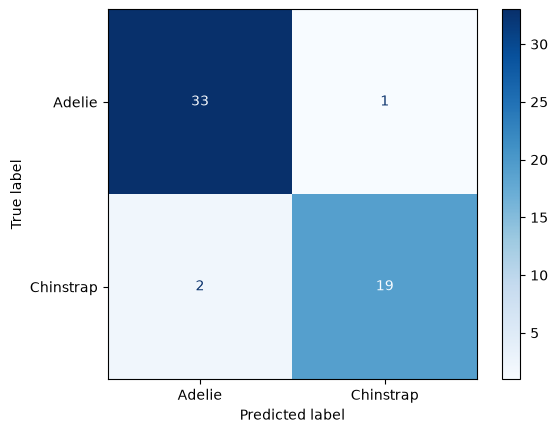

Test accuracy:  0.945
Train accuracy: 0.982


In [6]:
y_pred = classifier.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Adelie', 'Chinstrap']).plot(cmap='Blues')
plt.show()

print('Test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print('Train accuracy:', round(accuracy_score(y_train, classifier.predict(X_train_s)), 3))

## 6. Draw the decision boundary

We ask the model to classify every point on a grid and colour each cell by its answer. The boundary can bend. A larger `gamma` makes it wigglier.

C:\jtmp\ipykernel_41740\4282184188.py:10: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')


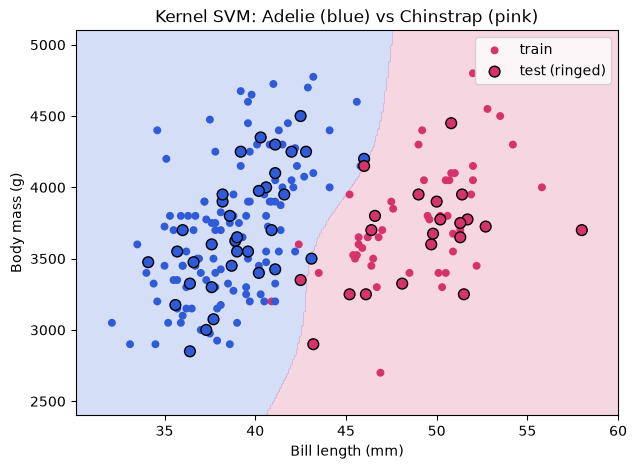

In [7]:
# a grid over the real units (mm and grams), scaled the same way as the training data
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

colors = ['#2f5bd8', '#d6336c']
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=[colors[v] for v in y_train], s=22, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')
plt.xlabel('Bill length (mm)')
plt.ylabel('Body mass (g)')
plt.title('Kernel SVM: Adelie (blue) vs Chinstrap (pink)')
plt.legend()
plt.show()

## Try it yourself

- Try `gamma=0.01`, `gamma=1` and `gamma=100`. Watch the training accuracy climb while the test accuracy falls.
- Change `kernel='rbf'` to `kernel='linear'` and compare the plots.

## See it: the decision boundary

Each coloured area is where the model answers "Adelie" (blue) or "Chinstrap" (raspberry). **Notice how** the boundary bends smoothly around the blue group instead of staying straight. The left panel shows the penguins the model learned from (filled dots). The right panel shows the penguins it has never seen (ringed dots): a ring sitting inside the wrong colour is a mistake. The accuracy is in each title.

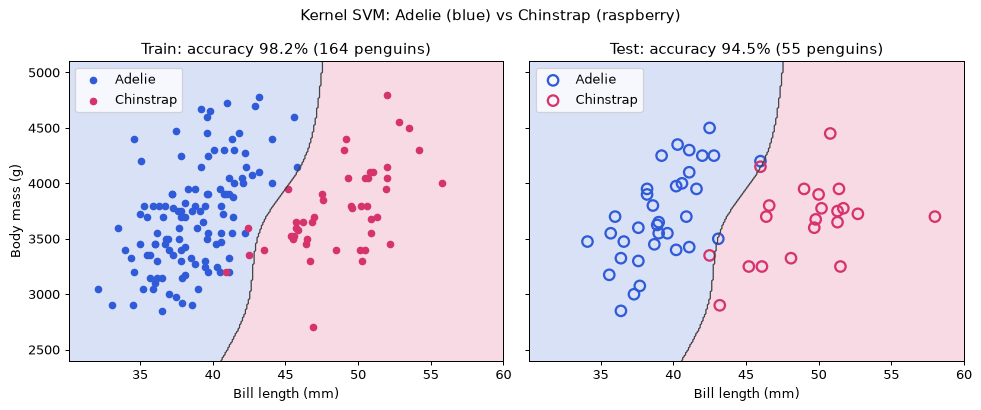

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
colors = [BLUE, PINK]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, Xp, yp, Xs in [(axes[0], 'Train', X_train, y_train, X_train_s),
                             (axes[1], 'Test', X_test, y_test, X_test_s)]:
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5], colors=colors)
    ax.contour(xx, yy, zz, levels=[0.5], colors='#444444', linewidths=1)
    acc = (classifier.predict(Xs) == yp).mean()
    for cls, label in [(0, 'Adelie'), (1, 'Chinstrap')]:
        pts = Xp[yp == cls]
        if name == 'Train':
            ax.scatter(pts[:, 0], pts[:, 1], color=colors[cls], s=26, label=label)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], facecolors='none', edgecolors=colors[cls], s=70, linewidths=1.8, label=label)
    ax.set_title(f'{name}: accuracy {acc:.1%} ({len(Xp)} penguins)')
    ax.set_xlabel('Bill length (mm)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Body mass (g)')
fig.suptitle('Kernel SVM: Adelie (blue) vs Chinstrap (raspberry)')
fig.tight_layout()
plt.show()
